# Survival analysis of breast cancer recurrence in Python
**Kaplan-Meier, Cox regression and survival prediction models (GBSG2 trial)**

Author: Ahmed Hamdy

## 1. Question and data
**Question:** which patient and tumour characteristics are associated with recurrence-free survival in node-positive breast cancer, and does hormonal therapy improve it?

**Data:** the German Breast Cancer Study Group 2 (GBSG2) trial (Schumacher et al. 1994), distributed with the `scikit-survival` package: 686 patients, 8 baseline variables, and the time to recurrence or death (or censoring). It is a public example dataset, so this notebook demonstrates the workflow, not a new clinical finding.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import logrank_test, proportional_hazard_test
from sklearn.model_selection import StratifiedKFold
from sksurv.datasets import load_gbsg2
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored

np.random.seed(123)
plt.rcParams["figure.dpi"] = 110
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

## 2. Load and describe the cohort
`cens` is `True` when the event (recurrence or death) was observed and `False` when the patient was censored. Time is converted from days to years.

In [2]:
X, y = load_gbsg2()
df = X.copy()
df["time_years"] = y["time"] / 365.25
df["event"] = y["cens"].astype(int)

print("Patients:", len(df))
print("Events:", int(df["event"].sum()), f"({df['event'].mean():.1%})")
print("Missing values:", int(df.isna().sum().sum()))

# Median follow-up with the reverse Kaplan-Meier method
fu = KaplanMeierFitter().fit(df["time_years"], 1 - df["event"])
print("Median follow-up (years):", round(fu.median_survival_time_, 2))

df.describe(include="all").T

Patients: 686
Events: 299 (43.6%)
Missing values: 0
Median follow-up (years): 4.5


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,686.0,NaN,NaN,NaN,53.052478,10.120739,21.0,46.0,53.0,61.0,80.0
estrec,686.0,NaN,NaN,NaN,96.252187,153.083963,0.0,8.0,36.0,114.0,1144.0
horTh,686,2,no,440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
menostat,686,2,Post,396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pnodes,686.0,NaN,NaN,NaN,5.010204,5.475483,1.0,1.0,3.0,7.0,51.0
progrec,686.0,NaN,NaN,NaN,109.995627,202.331552,0.0,7.0,32.5,131.75,2380.0
tgrade,686,3,II,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tsize,686.0,NaN,NaN,NaN,29.329446,14.296217,3.0,20.0,25.0,35.0,120.0
time_years,686.0,NaN,NaN,NaN,3.078685,1.759868,0.021903,1.554415,2.96783,4.612594,7.279945
event,686.0,NaN,NaN,NaN,0.43586,0.496231,0.0,0.0,0.0,1.0,1.0


## 3. Kaplan-Meier curves and log-rank test
Recurrence-free survival by hormonal therapy.

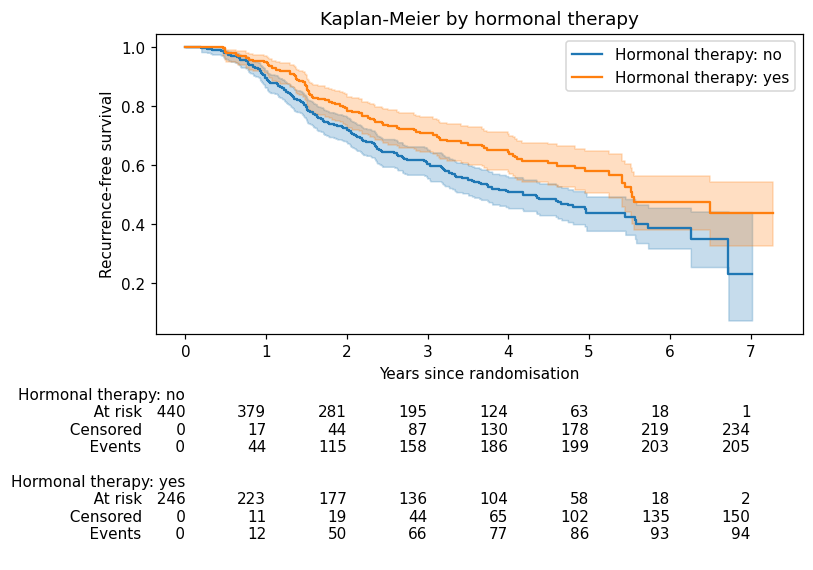

Log-rank test: chi2 = 8.56, p = 0.0034


In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
fitters = []
for group, sub in df.groupby("horTh", observed=True):
    km = KaplanMeierFitter(label=f"Hormonal therapy: {group}")
    km.fit(sub["time_years"], sub["event"])
    km.plot_survival_function(ax=ax)
    fitters.append(km)
add_at_risk_counts(*fitters, ax=ax)
ax.set_xlabel("Years since randomisation")
ax.set_ylabel("Recurrence-free survival")
ax.set_title("Kaplan-Meier by hormonal therapy")
plt.tight_layout()
plt.savefig("figures/km_by_hormonal_therapy.png", dpi=150)
plt.show()

yes = df[df["horTh"] == "yes"]
no = df[df["horTh"] == "no"]
lr = logrank_test(yes["time_years"], no["time_years"], yes["event"], no["event"])
print(f"Log-rank test: chi2 = {lr.test_statistic:.2f}, p = {lr.p_value:.4f}")

## 4. Multivariable Cox proportional hazards model
Variables are coded so hazard ratios are easy to read: age per year, tumour size per mm, number of positive nodes per node, tumour grade as an ordered score (I, II, III = 1, 2, 3), and the two hormone receptor values on a log2 scale (hazard ratio per doubling).

In [4]:
model_df = pd.DataFrame({
    "time_years": df["time_years"],
    "event": df["event"],
    "hormonal_therapy": (df["horTh"] == "yes").astype(int),
    "age": df["age"],
    "postmenopausal": (df["menostat"] == "Post").astype(int),
    "tumour_size_mm": df["tsize"],
    "tumour_grade": df["tgrade"].astype(str).map({"I": 1, "II": 2, "III": 3}).astype(int),
    "positive_nodes": df["pnodes"],
    "log2_progesterone_receptor": np.log2(df["progrec"] + 1),
    "log2_estrogen_receptor": np.log2(df["estrec"] + 1),
})
features = [c for c in model_df.columns if c not in ("time_years", "event")]

cph = CoxPHFitter()
cph.fit(model_df, duration_col="time_years", event_col="event")

hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)
hr.columns = ["hazard_ratio", "ci_low", "ci_high", "p_value"]
hr.to_csv("results/cox_hazard_ratios.csv")
print("Concordance index (training data):", round(cph.concordance_index_, 3))
hr

Concordance index (training data): 0.694


,hazard_ratio,ci_low,ci_high,p_value
covariate,,,,
hormonal_therapy,0.710,0.552,0.915,0.008
age,0.990,0.973,1.008,0.287
postmenopausal,1.262,0.881,1.808,0.204
tumour_size_mm,1.006,0.998,1.014,0.128
tumour_grade,1.207,0.971,1.499,0.090
positive_nodes,1.054,1.039,1.070,0.000
log2_progesterone_receptor,0.871,0.824,0.920,0.000
log2_estrogen_receptor,1.022,0.966,1.082,0.447


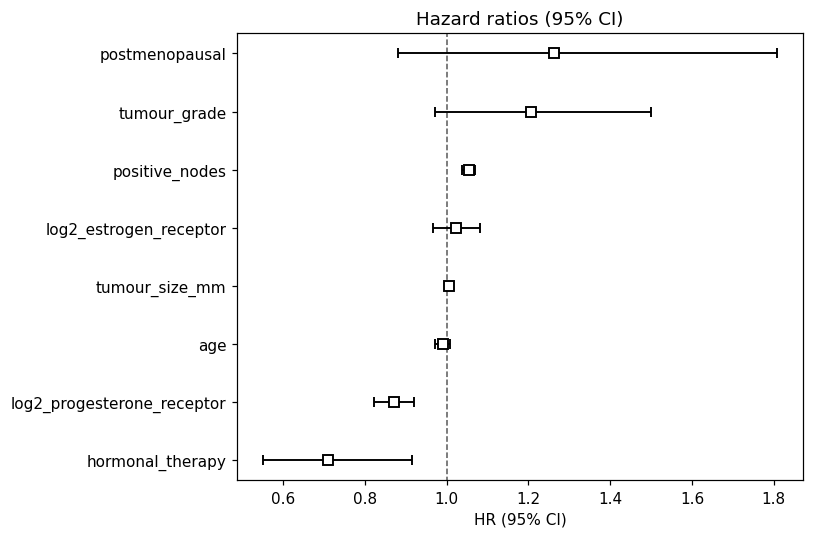

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5))
cph.plot(hazard_ratios=True, ax=ax)
ax.set_title("Hazard ratios (95% CI)")
plt.tight_layout()
plt.savefig("figures/cox_hazard_ratios.png", dpi=150)
plt.show()

### Proportional hazards assumption
The Cox model assumes each hazard ratio is constant over time. The test below uses rank-transformed time; small p-values suggest a violation.

In [6]:
ph = proportional_hazard_test(cph, model_df, time_transform="rank")
ph_table = ph.summary.round(3)
ph_table.to_csv("results/proportional_hazards_test.csv")
ph_table

,test_statistic,p,-log2(p)
age,3.500,0.061,4.026
hormonal_therapy,0.261,0.609,0.715
log2_estrogen_receptor,1.792,0.181,2.468
log2_progesterone_receptor,0.205,0.651,0.619
positive_nodes,0.388,0.533,0.907
postmenopausal,0.000,0.998,0.003
tumour_grade,3.372,0.066,3.914
tumour_size_mm,0.168,0.682,0.552


## 5. Prediction models: Cox vs random survival forest
Five-fold stratified cross-validation compares the discrimination (concordance index) of a Cox model and a random survival forest on data not used for fitting. A concordance index of 0.5 is chance and 1.0 is perfect ranking.

In [7]:
Xm = model_df[features]
ys = np.array(list(zip(model_df["event"].astype(bool), model_df["time_years"])),
              dtype=[("event", bool), ("time", float)])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
rows = []
for fold, (tr, te) in enumerate(skf.split(Xm, model_df["event"]), start=1):
    models = {
        "Cox regression": CoxPHSurvivalAnalysis(alpha=1e-4),
        "Random survival forest": RandomSurvivalForest(
            n_estimators=200, min_samples_leaf=15, random_state=123, n_jobs=-1),
    }
    for name, model in models.items():
        model.fit(Xm.iloc[tr], ys[tr])
        risk = model.predict(Xm.iloc[te])
        cindex = concordance_index_censored(ys[te]["event"], ys[te]["time"], risk)[0]
        rows.append({"fold": fold, "model": name, "c_index": cindex})

cv = pd.DataFrame(rows)
cv.to_csv("results/cross_validation_c_index.csv", index=False)
summary = cv.groupby("model")["c_index"].agg(["mean", "std"]).round(3)
summary

,mean,std
model,,
Cox regression,0.681,0.038
Random survival forest,0.692,0.031


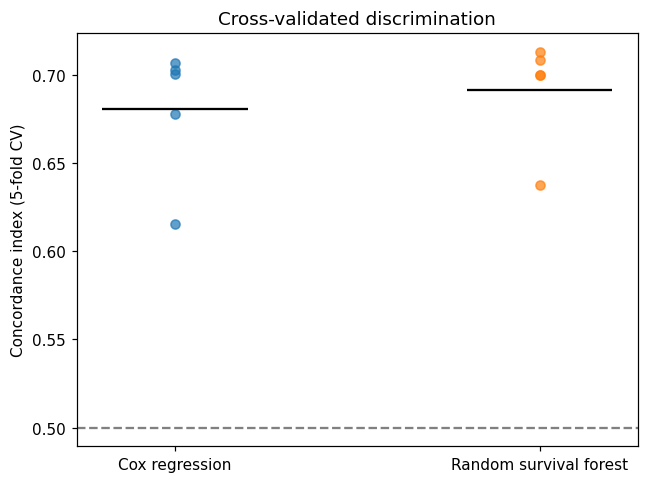

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, sub in cv.groupby("model"):
    ax.scatter([name] * len(sub), sub["c_index"], alpha=0.7)
    ax.hlines(sub["c_index"].mean(), -0.2 if name.startswith("Cox") else 0.8,
              0.2 if name.startswith("Cox") else 1.2, colors="black")
ax.axhline(0.5, linestyle="--", color="grey")
ax.set_ylabel("Concordance index (5-fold CV)")
ax.set_title("Cross-validated discrimination")
plt.tight_layout()
plt.savefig("figures/cv_concordance.png", dpi=150)
plt.show()

## 6. Limitations
- A single trial of 686 patients; results may not transfer to other populations.
- Hormonal therapy was randomised (2 x 2 design), but the other variables are observational, so their hazard ratios describe associations, not causes.
- The Cox model assumes proportional hazards; check the test above before relying on a single hazard ratio.
- Cross-validation estimates discrimination only; calibration and external validation were not assessed.
- The event combines recurrence and death, as defined in the dataset.

## 7. Reproducibility

In [9]:
import sys, sksurv, lifelines, sklearn
print("Python", sys.version.split()[0])
for pkg in (pd, np, sksurv, lifelines, sklearn):
    print(pkg.__name__, pkg.__version__)

Python 3.12.3
pandas 2.3.3
numpy 2.4.4
sksurv 0.28.0
lifelines 0.30.3
sklearn 1.9.1
